# Day 59: A mini modern data stack with DuckDB

UrbanKart Data Analyst Training. Install DuckDB first: pip install duckdb. Put the five CSV files (UrbanKart_orders.csv, UrbanKart_orders_2026-10.csv, UrbanKart_products.csv, UrbanKart_customers.csv, UrbanKart_returns.csv) in the same folder as this notebook and run the cells in order.

**Example.** Load the raw tables: orders from all UrbanKart_orders*.csv files (union_by_name), plus products, customers and returns. Show row counts.

In [1]:
import duckdb
con = duckdb.connect('urbankart.duckdb')

con.sql("""CREATE OR REPLACE TABLE raw_orders AS
  SELECT * FROM read_csv_auto('UrbanKart_orders*.csv', union_by_name = true)""")
for t in ['products', 'customers', 'returns']:
    con.sql(f"CREATE OR REPLACE TABLE raw_{t} AS SELECT * FROM read_csv_auto('UrbanKart_{t}.csv')")

con.sql("SELECT table_name, estimated_size AS row_count FROM duckdb_tables() ORDER BY 1").df()

      table_name  row_count
0  raw_customers        450
1     raw_orders       3293
2   raw_products         60
3    raw_returns        193

**T1.** Show the column types DuckDB detected for raw_orders.

In [2]:
con.sql('DESCRIBE raw_orders').df()[['column_name', 'column_type']]

      column_name column_type
0        order_id     VARCHAR
1      order_date        DATE
2     customer_id     VARCHAR
3      product_id     VARCHAR
4        quantity      BIGINT
5      unit_price      BIGINT
6    discount_pct      DOUBLE
7           sales      BIGINT
8            city     VARCHAR
9    payment_mode     VARCHAR
10   order_status     VARCHAR
11  delivery_date        DATE

**T2.** Profile raw_orders with SUMMARIZE: min, max, approx_unique, null_percentage.

In [3]:
prof = con.sql('SUMMARIZE raw_orders').df()
prof[['column_name', 'min', 'max', 'approx_unique', 'null_percentage']]

      column_name         min         max  approx_unique  null_percentage
0        order_id    UK100001    UK103292           3279              0.0
1      order_date  2025-01-01  2026-10-02            632              0.0
2     customer_id       C0001       C0450            458              0.0
3      product_id        P001        P060             60              0.0
4        quantity           1           4              4              0.0
5      unit_price         129       13999             38              0.0
6    discount_pct         0.0         0.2              5              0.0
7           sales         103       27998            440              0.0
8            city   Ahmedabad        Pune             11              0.0
9    payment_mode        Card      Wallet              5              0.0
10   order_status   Cancelled     Shipped              5              0.0
11  delivery_date  2025-01-03  2026-10-06            638              8.2

**T3.** Query UrbanKart_products.csv directly (no table): products and price range per category.

In [4]:
con.sql("""
SELECT category, COUNT(*) AS products,
       MIN(selling_price) AS min_price, MAX(selling_price) AS max_price
FROM 'UrbanKart_products.csv'
GROUP BY category ORDER BY category
""").df()

             category  products  min_price  max_price
0              Beauty        12        199       1999
1  Books & Stationery        12        129        899
2         Electronics        12        349      13999
3             Fashion        12        549       3499
4      Home & Kitchen        12        499       6499

**T4.** Create the staging view stg_orders (trim text, is_cancelled flag). Show the latest 6 orders.

In [5]:
con.sql("""
CREATE OR REPLACE VIEW stg_orders AS
SELECT order_id, order_date, customer_id, product_id,
       quantity, unit_price, discount_pct, sales,
       TRIM(city) AS city, TRIM(payment_mode) AS payment_mode,
       order_status, delivery_date,
       order_status = 'Cancelled' AS is_cancelled
FROM raw_orders
""")
con.sql('SELECT * FROM stg_orders ORDER BY order_date DESC LIMIT 6').df()

   order_id order_date customer_id product_id  quantity  unit_price  discount_pct  sales       city      payment_mode order_status delivery_date  is_cancelled
0  UK103291 2026-10-02       C0045       P002         1        2199           0.0   2199      Delhi  Cash on Delivery      Shipped           NaT         False
1  UK103292 2026-10-02       C0333       P040         3         349           0.0   1047    Chennai               UPI    Delivered    2026-10-06         False
2  UK103289 2026-10-01       C0112       P005         1        1299           0.0   1299       Pune               UPI    Delivered    2026-10-04         False
3  UK103290 2026-10-01       C0207       P021         2         899           0.1   1618  Bengaluru              Card     Delivred    2026-10-05         False
4  UK103285 2026-09-30       C0196       P019         1        1699           0.0   1699     Jaipur              Card      Shipped           NaT         False
5  UK103286 2026-09-30       C0254       P018 

**T5.** Write run_tests(con): unique order_id, order_date not null, valid status, product exists, sales not negative. Which tests fail?

In [6]:
def run_tests(con):
    return con.sql("""
    SELECT 'order_id is unique' AS test,
           COUNT(*) - COUNT(DISTINCT order_id) AS failures FROM stg_orders
    UNION ALL SELECT 'order_date not null',
           COUNT(*) FILTER (WHERE order_date IS NULL) FROM stg_orders
    UNION ALL SELECT 'status is valid',
           COUNT(*) FILTER (WHERE order_status NOT IN
             ('Delivered','Shipped','Returned','Cancelled')) FROM stg_orders
    UNION ALL SELECT 'product exists',
           COUNT(*) FILTER (WHERE p.product_id IS NULL)
           FROM stg_orders o LEFT JOIN raw_products p USING (product_id)
    UNION ALL SELECT 'sales not negative',
           COUNT(*) FILTER (WHERE sales < 0) FROM stg_orders
    """).df()

run_tests(con)

                  test  failures
0   order_id is unique         1
1  order_date not null         0
2      status is valid         1
3       product exists         0
4   sales not negative         0

**T6.** Investigate the duplicate order_id.

In [7]:
con.sql("""
SELECT * FROM raw_orders
WHERE order_id IN (SELECT order_id FROM raw_orders
                   GROUP BY order_id HAVING COUNT(*) > 1)
""").df()

   order_id order_date customer_id product_id  quantity  unit_price  discount_pct  sales    city      payment_mode order_status delivery_date
0  UK103288 2026-09-30       C0430       P002         1        2199          0.05   2089  Mumbai  Cash on Delivery     Returned    2026-10-02
1  UK103288 2026-09-30       C0430       P002         1        2199          0.05   2089  Mumbai  Cash on Delivery     Returned    2026-10-02

**T7.** Investigate the invalid status.

In [8]:
con.sql("""
SELECT order_id, order_date, order_status FROM stg_orders
WHERE order_status NOT IN ('Delivered','Shipped','Returned','Cancelled')
""").df()

   order_id order_date order_status
0  UK103290 2026-10-01     Delivred

**T8.** Fix both problems in stg_orders (QUALIFY ROW_NUMBER, CASE) and re-run the tests.

In [9]:
con.sql("""
CREATE OR REPLACE VIEW stg_orders AS
SELECT order_id, order_date, customer_id, product_id,
       quantity, unit_price, discount_pct, sales,
       TRIM(city) AS city, TRIM(payment_mode) AS payment_mode,
       CASE WHEN order_status = 'Delivred' THEN 'Delivered'
            ELSE order_status END AS order_status,
       delivery_date,
       order_status = 'Cancelled' AS is_cancelled
FROM raw_orders
QUALIFY ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY order_date) = 1
""")
run_tests(con)

                  test  failures
0   order_id is unique         0
1  order_date not null         0
2      status is valid         0
3       product exists         0
4   sales not negative         0

**T9.** Check row count vs distinct orders in stg_orders.

In [10]:
con.sql('SELECT COUNT(*) AS rows, COUNT(DISTINCT order_id) AS orders FROM stg_orders').df()

   rows  orders
0  3292    3292

**T10.** Logical + freshness test: deliveries before order date; latest order; days since latest (today = 2026-10-21).

In [11]:
con.sql("""
SELECT COUNT(*) FILTER (WHERE delivery_date < order_date) AS delivered_before_order,
       MAX(order_date) AS latest_order,
       DATE '2026-10-21' - MAX(order_date) AS days_since_latest
FROM stg_orders
""").df()

   delivered_before_order latest_order  days_since_latest
0                       0   2026-10-02                 19

**T11.** Build dim_date (2025–2026) with year, month, label and Indian fiscal year start.

In [12]:
con.sql("""
CREATE OR REPLACE TABLE dim_date AS
SELECT CAST(d AS DATE) AS date, YEAR(d) AS year, MONTH(d) AS month,
       strftime(d, '%b-%y') AS month_label,
       CASE WHEN MONTH(d) >= 4 THEN YEAR(d) ELSE YEAR(d) - 1 END AS fy_start
FROM range(DATE '2025-01-01', DATE '2027-01-01', INTERVAL 1 DAY) t(d)
""")
con.sql('SELECT COUNT(*) AS days, MIN(date) AS first, MAX(date) AS last FROM dim_date').df()

   days      first       last
0   730 2025-01-01 2026-12-31

**T12.** Check fiscal years around 1 April.

In [13]:
con.sql("SELECT date, month_label, fy_start FROM dim_date WHERE date IN ('2025-03-31','2025-04-01','2026-03-31','2026-04-01')").df()

        date month_label  fy_start
0 2025-03-31      Mar-25      2024
1 2025-04-01      Apr-25      2025
2 2026-03-31      Mar-26      2025
3 2026-04-01      Apr-26      2026

**T13.** Build fct_orders: join products + customers, gross_margin, order_month.

In [14]:
con.sql("""
CREATE OR REPLACE TABLE fct_orders AS
SELECT o.*, p.category, p.sub_category, c.region, c.segment,
       o.sales - p.cost_price * o.quantity AS gross_margin,
       DATE_TRUNC('month', o.order_date) AS order_month
FROM stg_orders o
LEFT JOIN raw_products p USING (product_id)
LEFT JOIN raw_customers c USING (customer_id)
""")
con.sql('SELECT order_id, category, region, sales, gross_margin, order_month FROM fct_orders LIMIT 5').df()

   order_id     category region  sales  gross_margin order_month
0  UK100001  Electronics  North   4398          1800  2025-01-01
1  UK100002  Electronics  South    349           200  2025-01-01
2  UK100003  Electronics   East   2199           900  2025-01-01
3  UK100004  Electronics   West    899           400  2025-01-01
4  UK100005      Fashion  South    899           500  2025-01-01

**T14.** Build mart_monthly: orders, sales, margin, margin %, AOV, cancel % (excluding cancelled where relevant).

In [15]:
con.sql("""
CREATE OR REPLACE TABLE mart_monthly AS
SELECT order_month,
       COUNT(*) AS orders,
       SUM(sales) FILTER (WHERE NOT is_cancelled) AS sales,
       SUM(gross_margin) FILTER (WHERE NOT is_cancelled) AS gross_margin,
       ROUND(100.0 * SUM(gross_margin) FILTER (WHERE NOT is_cancelled)
             / SUM(sales) FILTER (WHERE NOT is_cancelled), 1) AS margin_pct,
       ROUND(AVG(sales) FILTER (WHERE NOT is_cancelled), 0) AS aov,
       ROUND(100.0 * AVG(is_cancelled::INT), 1) AS cancel_pct
FROM fct_orders
GROUP BY order_month ORDER BY order_month
""")
con.sql('SELECT * FROM mart_monthly ORDER BY order_month DESC LIMIT 8').df()

  order_month  orders     sales  gross_margin  margin_pct     aov  cancel_pct
0  2026-10-01       4    6163.0        1470.0        23.9  1541.0         0.0
1  2026-09-01     207  443475.0      164774.0        37.2  2298.0         6.8
2  2026-08-01     231  499941.0      178373.0        35.7  2347.0         7.8
3  2026-07-01     202  485891.0      170548.0        35.1  2598.0         7.4
4  2026-06-01     192  431266.0      153783.0        35.7  2437.0         7.8
5  2026-05-01     192  461453.0      160273.0        34.7  2564.0         6.3
6  2026-04-01     179  366327.0      140685.0        38.4  2220.0         7.8
7  2026-03-01     197  406442.0      156099.0        38.4  2336.0        11.7

**T15.** Reconcile mart_monthly total sales with fct_orders.

In [16]:
con.sql("""
SELECT (SELECT SUM(sales) FROM mart_monthly) AS mart_total,
       (SELECT SUM(sales) FROM fct_orders WHERE NOT is_cancelled) AS fact_total
""").df()

   mart_total  fact_total
0   7167259.0   7167259.0

**T16.** Build mart_returns by category: returns, return %, refunds.

In [17]:
con.sql("""
CREATE OR REPLACE TABLE mart_returns AS
SELECT f.category,
       COUNT(*) AS delivered_or_returned,
       COUNT(r.order_id) AS returned,
       ROUND(100.0 * COUNT(r.order_id) / COUNT(*), 1) AS return_pct,
       SUM(r.refund_amount) AS refunds
FROM fct_orders f
LEFT JOIN raw_returns r USING (order_id)
WHERE f.order_status IN ('Delivered', 'Returned')
GROUP BY f.category ORDER BY return_pct DESC
""")
con.sql('SELECT * FROM mart_returns').df()

             category  delivered_or_returned  returned  return_pct   refunds
0      Home & Kitchen                    527        41         7.8  110762.0
1  Books & Stationery                    277        19         6.9   11776.0
2              Beauty                    484        31         6.4   40768.0
3             Fashion                    817        50         6.1  110790.0
4         Electronics                    917        52         5.7  162517.0

**T17.** Join a pandas DataFrame of targets (Jul–Sep 2026) to mart_monthly.

In [18]:
import pandas as pd
targets = pd.DataFrame({'month': pd.to_datetime(['2026-07-01', '2026-08-01', '2026-09-01']),
                        'target': [460000, 480000, 500000]})
con.sql("""
SELECT t.month::DATE AS month, m.sales, t.target,
       ROUND(100.0 * m.sales / t.target - 100, 1) AS vs_target_pct
FROM targets t JOIN mart_monthly m ON m.order_month = t.month
ORDER BY month
""").df()

       month     sales  target  vs_target_pct
0 2026-07-01  485891.0  460000            5.6
1 2026-08-01  499941.0  480000            4.2
2 2026-09-01  443475.0  500000          -11.3

**T18.** PIVOT: 2026 monthly sales (₹ lakh) by category.

In [19]:
con.sql("""
PIVOT (SELECT strftime(order_month, '%Y-%m') AS month, category, sales / 1e5 AS sales_lakh
       FROM fct_orders
       WHERE NOT is_cancelled AND order_month >= DATE '2026-01-01'
         AND order_month < DATE '2026-10-01')
ON category USING ROUND(SUM(sales_lakh), 2)
ORDER BY month
""").df()

     month  Beauty  Books & Stationery  Electronics  Fashion  Home & Kitchen
0  2026-01    0.36                0.12         1.43     0.71            0.59
1  2026-02    0.35                0.07         1.56     0.97            0.61
2  2026-03    0.35                0.06         1.44     1.23            0.99
3  2026-04    0.39                0.06         1.53     1.01            0.68
4  2026-05    0.34                0.09         2.62     0.72            0.85
5  2026-06    0.39                0.04         2.32     0.86            0.70
6  2026-07    0.20                0.06         2.71     1.12            0.77
7  2026-08    0.35                0.11         2.66     1.24            0.64
8  2026-09    0.33                0.13         1.80     1.38            0.80

**T19.** Export mart_monthly and fct_orders to Parquet (and fct_orders to CSV). Compare file sizes.

In [20]:
con.sql("COPY mart_monthly TO 'mart_monthly.parquet' (FORMAT parquet)")
con.sql("COPY fct_orders TO 'mart_fct_orders.parquet' (FORMAT parquet)")
con.sql("COPY fct_orders TO 'mart_fct_orders.csv' (HEADER)")
import os
for f in ['mart_fct_orders.parquet', 'mart_fct_orders.csv']:
    print(f, round(os.path.getsize(f) / 1024), 'KB')

mart_fct_orders.parquet 69 KB
mart_fct_orders.csv 474 KB


**T20.** Query the Parquet file directly: sales (₹ lakh) and margin % by category.

In [21]:
con.sql("""
SELECT category, ROUND(SUM(sales) / 1e5, 2) AS sales_lakh,
       ROUND(100.0 * SUM(gross_margin) / SUM(sales), 1) AS margin_pct
FROM 'mart_fct_orders.parquet'
WHERE NOT is_cancelled
GROUP BY category ORDER BY sales_lakh DESC
""").df()

             category  sales_lakh  margin_pct
0         Electronics       34.24        31.4
1             Fashion       17.68        41.7
2      Home & Kitchen       12.90        37.4
3              Beauty        5.36        41.1
4  Books & Stationery        1.50        41.6

**T21.** Chart monthly sales from mart_monthly (exclude partial October).

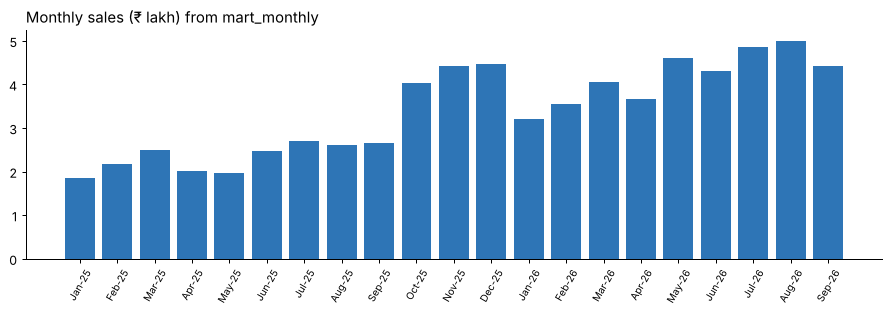

In [22]:
import matplotlib.pyplot as plt
m = con.sql("SELECT * FROM mart_monthly WHERE order_month < DATE '2026-10-01' ORDER BY order_month").df()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(m['order_month'].dt.strftime('%b-%y'), m['sales'] / 1e5, color='#2E75B6')
ax.set_title('Monthly sales (₹ lakh) from mart_monthly', loc='left')
ax.tick_params(axis='x', rotation=60, labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**T22.** Document fct_orders with COMMENT ON and read the comment back.

In [23]:
con.sql("COMMENT ON TABLE fct_orders IS 'One row per order (deduplicated). Built from stg_orders + products + customers.'")
con.sql("COMMENT ON COLUMN fct_orders.gross_margin IS 'sales - cost_price * quantity (INR)'")
con.sql("""
SELECT table_name, comment FROM duckdb_tables()
WHERE table_name = 'fct_orders'
""").df()

   table_name                                                                          comment
0  fct_orders  One row per order (deduplicated). Built from stg_orders + products + customers.

**T23.** Your own test: count orders where delivery_date < order_date in fct_orders, and add a mart of monthly sales by region.

In [24]:
print(con.sql('SELECT COUNT(*) FROM fct_orders WHERE delivery_date < order_date').fetchall())
con.sql("""
SELECT order_month, region, SUM(sales) FILTER (WHERE NOT is_cancelled) AS sales
FROM fct_orders GROUP BY ALL ORDER BY order_month DESC, region LIMIT 8
""").df()

[(0,)]


  order_month   region     sales
0  2026-10-01    South    2917.0
1  2026-10-01     West    3246.0
2  2026-09-01  Central   25292.0
3  2026-09-01     East   38444.0
4  2026-09-01    North   85408.0
5  2026-09-01    South  156344.0
6  2026-09-01     West  137987.0
7  2026-08-01  Central   18604.0